In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [40]:
ecoles = pd.read_csv('ecoles.csv', sep = ';')
ecoles
# Ce data set indique pour chaque école française l'indice de position sociale
# (calculé en fonction de la CSP des parents),
# et les informations géographiques et administratives de l'école

,Rentrée scolaire,Académie,Code du département,Département,UAI,Nom de l'établissment,Code INSEE de la commune,Nom de la commune,Secteur,IPS
0,2018-2019,ROUEN,027,EURE,0270509G,ECOLE PRIMAIRE,27034,BACQUEVILLE,public,87.7
1,2018-2019,ROUEN,027,EURE,0270511J,ECOLE PRIMAIRE,27104,BOURG BEAUDOUIN,public,98.6
2,2018-2019,ROUEN,027,EURE,0270591W,ECOLE PRIMAIRE,27480,PUCHAY,public,93.9
3,2018-2019,ROUEN,027,EURE,0270637W,ECOLE PRIMAIRE ALBERT BECQUART,27386,LE MANOIR,public,94.0
4,2018-2019,ROUEN,027,EURE,0270640Z,ECOLE PRIMAIRE,27412,TERRES DE BORD,public,112.7
...,...,...,...,...,...,...,...,...,...,...
182077,2020-2021,GRENOBLE,073,SAVOIE,0730471R,ECOLE ELEMENTAIRE BRAMANS,73290,VAL CENIS,public,114.5
182078,2020-2021,GRENOBLE,073,SAVOIE,0730482C,ECOLE PRIMAIRE,73023,AUSSOIS,public,110.9
182079,2020-2021,GRENOBLE,073,SAVOIE,0730544V,ECOLE ELEMENTAIRE,73083,LES CHAVANNES EN MAURIENNE,public,99.8
182080,2020-2021,GRENOBLE,073,SAVOIE,0730557J,ECOLE PRIMAIRE,73255,SAINTE MARIE DE CUINES,public,101.2


In [75]:
# On va comparer les IPS des écoles publiques et privées'

In [76]:
public = data[data['Secteur'] == 'public']
print('IPS moyen secteur public : ' + str(np.mean(public['IPS'])))
prive = data[data['Secteur'] == 'privé sous contrat']
print('IPS moyen secteur privé : ' + str(np.mean(prive['IPS'])))

IPS moyen secteur public : 101.20247430334217
IPS moyen secteur privé : 111.88908886824586


In [61]:
pib = pd.read_csv('pib.csv')
pib
# Ce data set indique le PIB par habitant pour chaque département

,Code_departement,PIB_par_habitant_2022,PIB_par_habitant_2019
0,092,117059,115684
1,075,122918,113813
2,069,53426,49536
3,078,41804,42141
4,031,43460,43141
...,...,...,...
91,070,24630,21333
92,024,26303,23445
93,062,27405,24367
94,02B,27188,24872


In [80]:
IPSmoyen = ecoles.groupby('Code du département').IPS.mean()
IPSmoyen
# Ce data set indique l'IPS moyen des écoles du département

Code du département
001    107.123921
002     91.171925
003     98.514694
004    102.894700
005    108.843446
          ...    
971     86.196056
972     88.157188
973     72.567206
974     80.366748
976     68.706356
Name: IPS, Length: 101, dtype: float64

In [63]:
donnees_finales = pd.merge(IPSmoyen,pib, left_on = 'Code du département', right_on = 'Code_departement')
donnees_finales
# Ce data set indique l'IPS moyen des écoles du département et le PIB par habitant pour chaque département

,IPS,Code_departement,PIB_par_habitant_2022,PIB_par_habitant_2019
0,107.123921,001,27443,26440
1,91.171925,002,26629,23410
2,98.514694,003,28080,25066
3,102.894700,004,28571,25817
4,108.843446,005,30694,26897
...,...,...,...,...
91,110.153855,091,44815,42471
92,119.724620,092,117059,115684
93,89.871423,093,41374,41063
94,105.895972,094,42192,40128


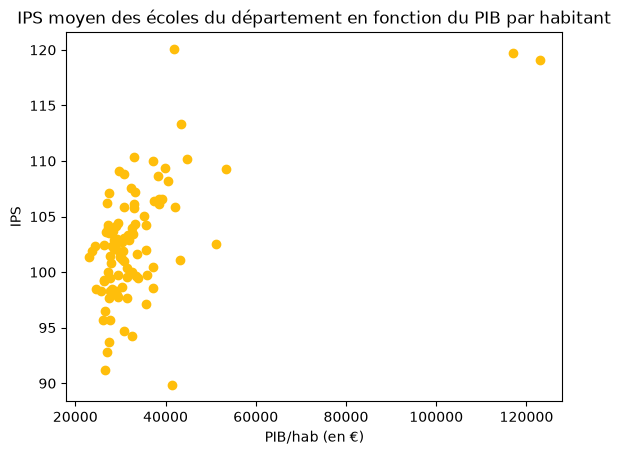

In [85]:
plt.figure(1)
X = donnees_finales['PIB_par_habitant_2022']
Y = donnees_finales['IPS']
plt.title('IPS moyen des écoles du département en fonction du PIB par habitant')
plt.scatter(X,Y,color='#ffbe0b')
plt.xlabel('PIB/hab (en €)')
plt.ylabel('IPS')
plt.show()

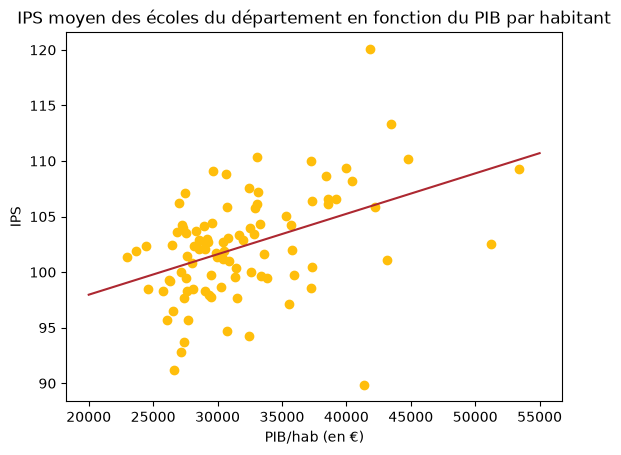

In [87]:
# On exclu Paris et les Hauts-de-Seine pour y voir plus clair
donnees_coupees = donnees_finales[donnees_finales['PIB_par_habitant_2019'] <= 100000]

plt.figure(2)
X = donnees_coupees['PIB_par_habitant_2022']
Y = donnees_coupees['IPS']
(a,b) = np.polyfit(X, Y, 1)
plt.plot([20000,55000],[a*20000+b,a*55000+b],color='#ad2831')
plt.title('IPS moyen des écoles du département en fonction du PIB par habitant')
plt.scatter(X,Y,color='#ffbe0b')
plt.xlabel('PIB/hab (en €)')
plt.ylabel('IPS')

plt.show()

# On observe que le niveau social des parents des élèves croît avec la richesse du département, c'était attendu
# Mais la corrélation n'est pas très forte, cherchons un meilleur paramètre

In [69]:
revenus = pd.read_csv('nivvie.csv')
revenus['code_departement'] = revenus['code_departement'].astype(str).str.zfill(3)
revenus
# Ce data set indique le revenu médian des habitants de chaque département

,code_departement,departement,niveau_vie_median_euros,premier_decile_euros,neuvieme_decile_euros
0,001,Ain,27990,14490,53240
1,002,Aisne,23360,12600,38580
2,003,Allier,24430,13210,39630
3,004,Alpes-de-Haute-Provence,24240,12690,41090
4,005,Hautes-Alpes,25060,13870,41460
...,...,...,...,...,...
93,093,Seine-Saint-Denis,21250,10000,41280
94,094,Val-de-Marne,27250,12090,53350
95,095,Val-d'Oise,25890,11970,46220
96,00M,France métropolitaine,25920,13200,46500


In [71]:
donnees_finales2 = pd.merge(IPSmoyen,revenus, left_on = 'Code du département', right_on = 'code_departement')
donnees_finales2
# Ici, on a pour chaque département l'IPS moyen des écoles et le revenu médian des habitants

,IPS,code_departement,departement,niveau_vie_median_euros,premier_decile_euros,neuvieme_decile_euros
0,107.123921,001,Ain,27990,14490,53240
1,91.171925,002,Aisne,23360,12600,38580
2,98.514694,003,Allier,24430,13210,39630
3,102.894700,004,Alpes-de-Haute-Provence,24240,12690,41090
4,108.843446,005,Hautes-Alpes,25060,13870,41460
...,...,...,...,...,...,...
92,119.724620,092,Hauts-de-Seine,33790,13720,71120
93,89.871423,093,Seine-Saint-Denis,21250,10000,41280
94,105.895972,094,Val-de-Marne,27250,12090,53350
95,105.807701,095,Val-d'Oise,25890,11970,46220


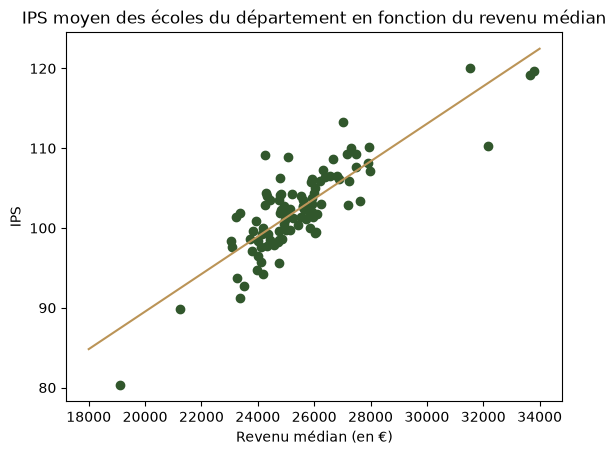

In [90]:
plt.figure(3)
X = donnees_finales2['niveau_vie_median_euros']
Y = donnees_finales2['IPS']
plt.scatter(X,Y,color='#31572c')
(a,b) = np.polyfit(X, Y, 1)
plt.plot([18000,34000],[a*18000+b,a*34000+b],color='#bb9457')
plt.title('IPS moyen des écoles du département en fonction du revenu médian')
plt.xlabel('Revenu médian (en €)')
plt.ylabel('IPS')
plt.show()

In [ ]:
# La catégorie sociale des parents est très étroitement corrélée au revenu des habitants du département
# La corrélation est bien meilleure